# Laboratorium 4 — sumowanie z opóźnionymi znacznikami

Wymagane pakiety: `torch`, `numpy`, `pandas`, `matplotlib`.

## 1. Dane i kontrola generatora

In [1]:
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED, DELAY = 42, 8
N_TRAIN, N_TEST = 4096, 1024
EPOCHS, BATCH_SIZE, LR = 30, 128, 0.003
DEVICE = torch.device("cpu")
torch.set_num_threads(2)
rng = np.random.default_rng(SEED)


def generate_data(n, length):
    x = np.zeros((n, length, 2), dtype=np.float32)
    x[:, :, 0] = rng.random((n, length), dtype=np.float32)
    markers = np.array([
        rng.choice(length - DELAY, size=2, replace=False) + DELAY
        for _ in range(n)
    ])
    rows = np.arange(n)[:, None]
    x[rows, markers, 1] = 1
    y = x[rows, markers - DELAY, 0].sum(axis=1)
    return torch.from_numpy(x), torch.from_numpy(y)


data = {
    length: (generate_data(N_TRAIN, length), generate_data(N_TEST, length))
    for length in (50, 100)
}

x_train, y_train = data[50][0]
markers = torch.where(x_train[0, :, 1] == 1)[0]
sources = markers - DELAY
value_a, value_b = x_train[0, sources, 0].tolist()
manual_sum = value_a + value_b
assert np.isclose(manual_sum, y_train[0].item())
display(pd.Series({
    "Znaczniki (kroki)": (markers + 1).tolist(),
    "Wskazane kroki": (sources + 1).tolist(),
    "Wartości": [value_a, value_b],
    "Suma ręczna": manual_sum,
    "Cel generatora": y_train[0].item(),
}))

Znaczniki (kroki)                                     [26, 48]
Wskazane kroki                                        [18, 40]
Wartości             [0.12811362743377686, 0.6316643953323364]
Suma ręczna                                           0.759778
Cel generatora                                        0.759778
dtype: object

## 2. Modele i pomiar treningu

In [2]:
class Recurrent(nn.Module):
    def __init__(self, layer, hidden):
        super().__init__()
        self.recurrent = layer(2, hidden, batch_first=True)
        self.readout = nn.Linear(hidden, 1)

    def forward(self, x):
        sequence, _ = self.recurrent(x)
        return self.readout(sequence[:, -1]).squeeze(-1)


class ConvModel(nn.Module):
    def __init__(self, dilations):
        super().__init__()
        layers = []
        in_channels = 2
        for dilation in dilations:
            layers.extend([
                nn.Conv1d(in_channels, 32, 3, padding=dilation, dilation=dilation),
                nn.ReLU(),
            ])
            in_channels = 32
        self.features = nn.Sequential(*layers)
        self.readout = nn.Linear(32, 1)

    def forward(self, x):
        features = self.features(x.transpose(1, 2))
        return self.readout(features.mean(dim=2)).squeeze(-1)


def train_and_test(model, train, test):
    model = model.to(DEVICE)
    loader = DataLoader(
        TensorDataset(*train), batch_size=BATCH_SIZE, shuffle=True,
        generator=torch.Generator().manual_seed(SEED),
    )
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    loss = nn.MSELoss()
    model.train()
    start = perf_counter()
    for _ in range(EPOCHS):
        for x, y in loader:
            optimizer.zero_grad()
            loss(model(x.to(DEVICE)), y.to(DEVICE)).backward()
            optimizer.step()
    seconds = perf_counter() - start

    model.eval()
    x_test, y_test = test
    with torch.inference_mode():
        prediction = torch.cat([
            model(batch.to(DEVICE)).cpu() for batch in x_test.split(BATCH_SIZE)
        ])
    mse = loss(prediction, y_test).item()
    parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return mse, seconds, parameters, prediction

## 3. Porównanie modeli i wariantów

In [3]:
recurrent_layers = {"SimpleRNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}
dilated, undilated = (1, 2, 4), (1, 1, 1)
main_models = [*recurrent_layers, "Conv1D"]
results, predictions = [], {}

for length, (train, test) in data.items():
    _, y_train = train
    _, y_test = test
    baseline = (y_test - y_train.mean()).square().mean().item()
    results.append((length, "Predykcja stała", baseline, None, None))

    models = main_models.copy()
    if length == 100:
        models.extend(["SimpleRNN 64", "Conv1D [1, 1, 1]"])
    for name in models:
        torch.manual_seed(SEED)
        if name.startswith("Conv1D"):
            dilations = undilated if name == "Conv1D [1, 1, 1]" else dilated
            model = ConvModel(dilations)
        else:
            architecture = recurrent_layers[name.split()[0]]
            hidden = 64 if name == "SimpleRNN 64" else 32
            model = Recurrent(architecture, hidden)

        mse, seconds, parameters, prediction = train_and_test(model, train, test)
        results.append((length, name, mse, seconds, parameters))
        predictions[length, name] = prediction

results = pd.DataFrame(
    results, columns=["L", "Model", "Test MSE", "Czas [s]", "Parametry"],
)
results["Parametry"] = results["Parametry"].astype("Int64")
display(results.round({"Test MSE": 6, "Czas [s]": 2}))

,L,Model,Test MSE,Czas [s],Parametry
0,50,Predykcja stała,0.172694,NaN,<NA>
1,50,SimpleRNN,0.174929,4.94,1185
2,50,LSTM,0.174600,4.44,4641
3,50,GRU,0.169589,11.34,3489
4,50,Conv1D,0.166116,4.15,6465
5,100,Predykcja stała,0.176067,NaN,<NA>
6,100,SimpleRNN,0.176892,7.71,1185
7,100,LSTM,0.176628,9.33,4641
8,100,GRU,0.175213,23.25,3489
9,100,Conv1D,0.172629,6.10,6465


## 4. Wykres, pole recepcyjne i przykład dużego błędu

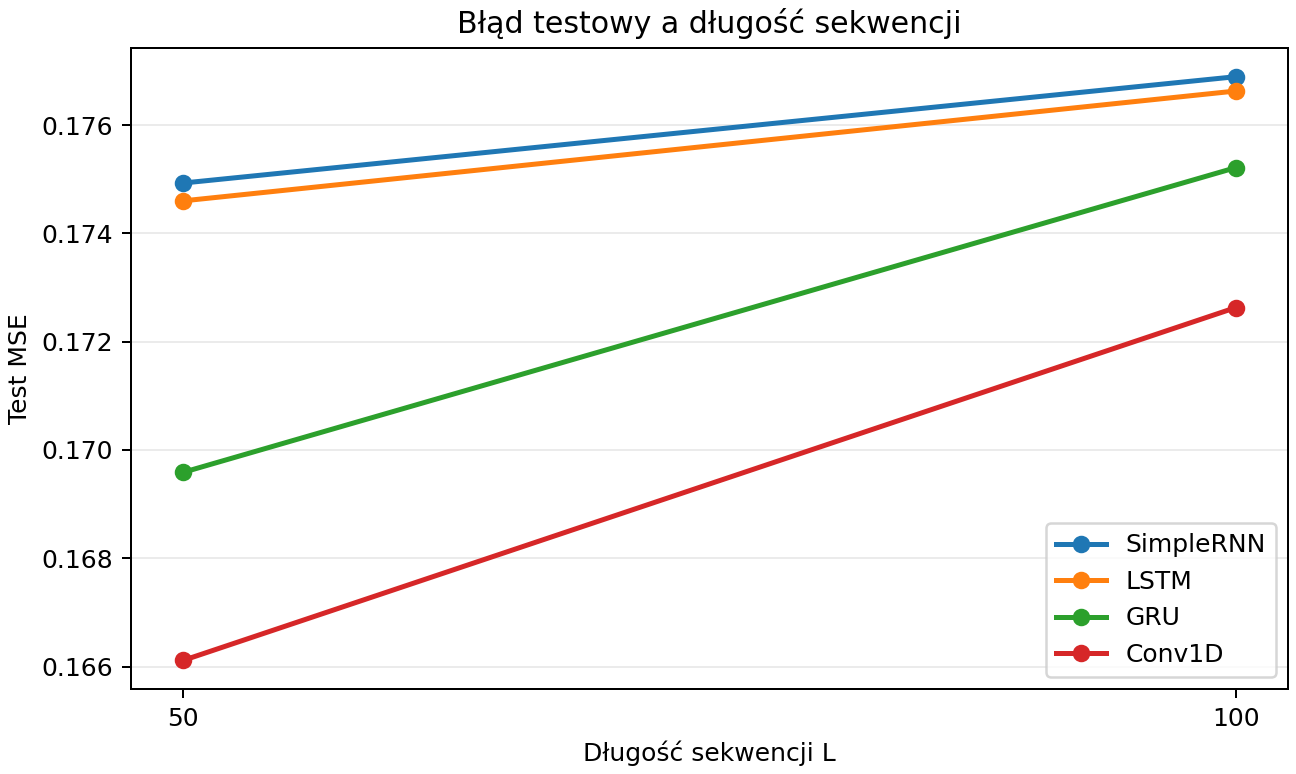

In [4]:
fig, ax = plt.subplots(figsize=(7.2, 4.3), layout="constrained")
for name in main_models:
    rows = results[results["Model"] == name]
    ax.plot(rows["L"], rows["Test MSE"], "o-", linewidth=2, label=name)
ax.set(
    xlabel="Długość sekwencji L", ylabel="Test MSE", xticks=[50, 100],
    title="Błąd testowy a długość sekwencji",
)
ax.grid(axis="y", alpha=0.25)
ax.legend()
fig.savefig("test_mse_lab4.png", dpi=180)
plt.show()

In [5]:
fields = pd.DataFrame([
    (str(list(dilations)), 1 + 2 * sum(dilations), 2 * sum(dilations) >= DELAY)
    for dilations in (dilated, undilated)
], columns=["Dylatacje", "Pole recepcyjne", "Para mieści się w polu"])
display(fields)

x_test, y_test = data[100][1]
prediction = predictions[100, "SimpleRNN"]
index = (y_test - prediction).square().argmax().item()
markers = torch.where(x_test[index, :, 1] == 1)[0]
sources = markers - DELAY
display(pd.Series({
    "Numer przykładu testowego": index + 1,
    "Znaczniki (kroki)": (markers + 1).tolist(),
    "Wskazane kroki": (sources + 1).tolist(),
    "Wartości": x_test[index, sources, 0].tolist(),
    "Cel": y_test[index].item(),
    "Predykcja": prediction[index].item(),
    "Błąd kwadratowy": (y_test[index] - prediction[index]).square().item(),
}))

,Dylatacje,Pole recepcyjne,Para mieści się w polu
0,"[1, 2, 4]",15,True
1,"[1, 1, 1]",7,False


Numer przykładu testowego                                        87
Znaczniki (kroki)                                          [56, 57]
Wskazane kroki                                             [48, 49]
Wartości                     [0.960809051990509, 0.990469753742218]
Cel                                                        1.951279
Predykcja                                                  0.959525
Błąd kwadratowy                                            0.983575
dtype: object